## 1. Import Required Libraries

In [4]:
# Import required libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


## 2. Define configuration parameters

In [5]:
# Define dataset and model parameters

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
RANDOM_SEED = 42

# Identify the project root directory
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Define the processed dataset path
PROCESSED_PATH = PROJECT_ROOT / "dataset" / "processed"

print("Project Root:", PROJECT_ROOT)
print("Processed Dataset Path:", PROCESSED_PATH)
print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Random Seed:", RANDOM_SEED)
print("Processed Dataset Exists:", PROCESSED_PATH.exists())

Project Root: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION
Processed Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\processed
Image Size: (224, 224)
Batch Size: 32
Epochs: 10
Random Seed: 42
Processed Dataset Exists: True


## Inference 
The dataset and model configuration parameters were defined successfully. The image size was set to 224 × 224 pixels, the batch size to 32, the number of training epochs to 10, and the random seed to 42. The processed dataset directory was also identified for loading the preprocessed images during CNN model development.

## 3. Load images from the processed dataset

In [6]:
# Load processed images from the dataset directory

dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("Dataset loaded successfully!")
print("Class names:", dataset.class_names)
print("Number of classes:", len(dataset.class_names))

Found 949 files belonging to 2 classes.
Dataset loaded successfully!
Class names: ['Defective', 'Non defective']
Number of classes: 2


## 3.1 Check the dataset shape

In [7]:
# Check image and label shapes

for images, labels in dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>


## 3.2 Visualize loaded dataset images

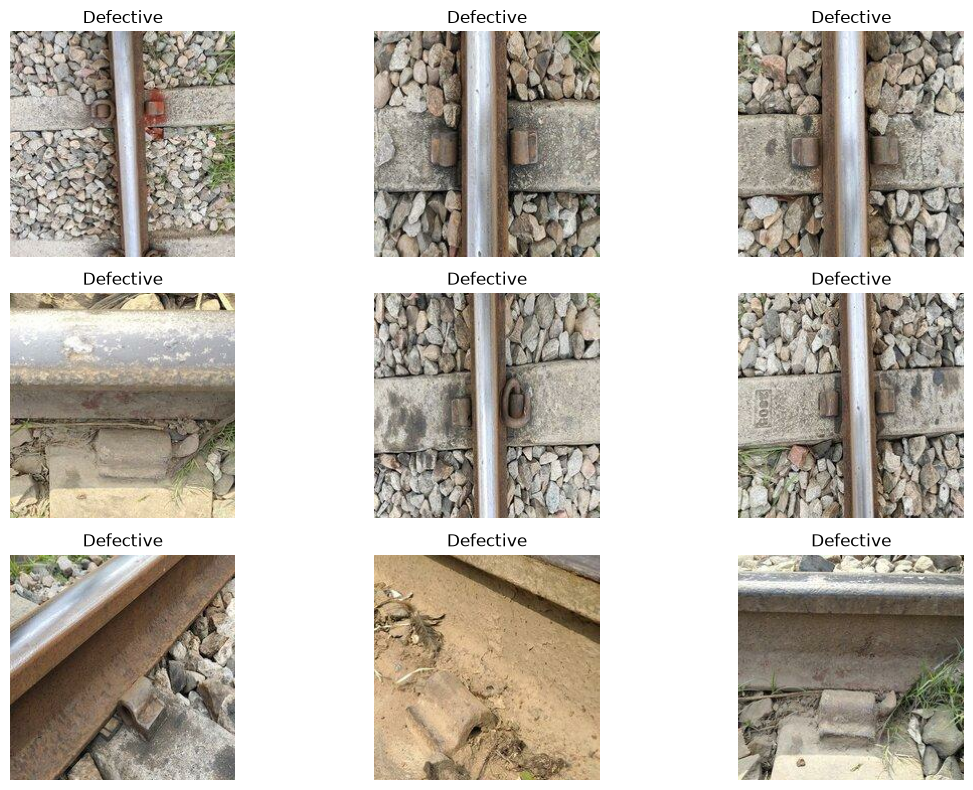

In [8]:
# Visualize images loaded from the processed dataset

plt.figure(figsize=(12, 8))

for images, labels in dataset.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(dataset.class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

## Inference
The preprocessed railway image dataset was loaded successfully using TensorFlow's image_dataset_from_directory() function. The images were organized into batches, and class labels were automatically assigned based on their respective folder names. The dataset structure, image dimensions, label information, and sample images were verified to ensure that the data is ready for the next stage of CNN model development.

## 4. Encode Class Labels

## 4.1 Display class label mapping

In [9]:
# Display class names and their numerical labels

class_names = dataset.class_names

class_mapping = {
    index: name for index, name in enumerate(class_names)
}

print("Class Label Mapping:\n")

for label, class_name in class_mapping.items():
    print(label, ":", class_name)

print("\nTotal number of classes:", len(class_names))

Class Label Mapping:

0 : Defective
1 : Non defective

Total number of classes: 2


## Inference
The class names were successfully mapped to numerical labels based on the dataset directory structure. Each category was assigned a unique integer label, which allows the CNN model to perform multi-class image classification using numerical target values.

## 4.2 Check the distribution of class labels

In [10]:
# Check the number of images in each class

label_counts = np.zeros(len(class_names), dtype=int)

for images, labels in dataset:
    label_counts += np.bincount(
        labels.numpy(),
        minlength=len(class_names)
    )

print("Image distribution across classes:\n")

for i, class_name in enumerate(class_names):
    print(f"{class_name}: {label_counts[i]} images")

Image distribution across classes:

Defective: 478 images
Non defective: 471 images


## Inference
The number of images available in each class was calculated to examine the distribution of the dataset. This analysis helps identify whether the dataset is balanced or imbalanced across different railway image categories, which may influence the model training process.

## 5. Split Dataset into Training and Testing Sets

## 5.1 Split the dataset (80% training, 20% testing)

In [11]:
# Split dataset into training and testing sets

train_dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    validation_split=0.2,
    subset="training",
    seed=RANDOM_SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

print("Training dataset created successfully!")
print("Testing dataset created successfully!")

Found 949 files belonging to 2 classes.
Using 760 files for training.
Found 949 files belonging to 2 classes.
Using 189 files for validation.
Training dataset created successfully!
Testing dataset created successfully!


## 5.2 Verify the dataset split

In [12]:
# Verify training and testing datasets

print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

print("Training classes:", train_dataset.class_names)
print("Testing classes:", test_dataset.class_names)

Training batches: 24
Testing batches: 6
Training classes: ['Defective', 'Non defective']
Testing classes: ['Defective', 'Non defective']


## Inference
The dataset was divided into training and testing subsets using an 80:20 split. The training dataset is used to learn image features and classification patterns, while the testing dataset is reserved for evaluating the model's performance on unseen images. A fixed random seed was used to ensure reproducibility of the dataset split.

## 6 Build CNN Architecture

## 6.1 Create the CNN model

In [13]:
# Build CNN architecture

num_classes = len(class_names)

cnn_model = models.Sequential([
    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction and classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(num_classes, activation="softmax")
])

print("CNN model architecture created successfully!")
print("Number of classes:", num_classes)

CNN model architecture created successfully!
Number of classes: 2


## Inference
A Convolutional Neural Network (CNN) architecture was developed for railway image classification. The model consists of convolutional layers with 32, 64, and 128 filters to extract image features at different levels, followed by max pooling layers to reduce spatial dimensions. Global average pooling, a dense layer, and dropout were incorporated to support feature learning and reduce overfitting. The final softmax output layer was configured according to the number of image classes.

## 7. Compile the CNN Model

## 7.1 Compile the model

In [14]:
# Compile CNN model

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


## Inference
The CNN model was compiled successfully using the Adam optimizer and sparse categorical crossentropy loss function. Accuracy was selected as the evaluation metric to monitor the model's classification performance during training. These configurations prepare the CNN model for the training process.

## 8. Model Architecture Summary

## 8.1 Display model summary

In [15]:
# Display CNN model architecture summary

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,018 (429.76 KB)

 Trainable params: 110,018 (429.76 KB)

 Non-trainable params: 0 (0.00 B)

## Inference
The CNN architecture was examined using the model summary. The summary provides details about the model layers, output dimensions, and trainable parameters. This verification confirms that the CNN structure is configured correctly and is ready for training.

## 9. Train the CNN Model

## 9.1 Train the model

In [16]:
# Train the CNN model

history = cnn_model.fit(
    train_dataset,
    epochs=EPOCHS,
    validation_data=test_dataset
)

print("CNN model training completed!")

Epoch 1/10


c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


24/24 ━━━━━━━━━━━━━━━━━━━━ 22s 832ms/step - accuracy: 0.5171 - loss: 2.9566 - val_accuracy: 0.4921 - val_loss: 0.7071
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 800ms/step - accuracy: 0.5171 - loss: 0.7299 - val_accuracy: 0.5026 - val_loss: 0.6983
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 815ms/step - accuracy: 0.5342 - loss: 0.6919 - val_accuracy: 0.6243 - val_loss: 0.6787
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 803ms/step - accuracy: 0.6474 - loss: 0.6520 - val_accuracy: 0.6190 - val_loss: 0.6626
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 845ms/step - accuracy: 0.6671 - loss: 0.6462 - val_accuracy: 0.6402 - val_loss: 0.6771
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 810ms/step - accuracy: 0.6868 - loss: 0.6187 - val_accuracy: 0.6561 - val_loss: 0.6508
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 806ms/step - accuracy: 0.6947 - loss: 0.6004 - val_accuracy: 0.6349 - val_loss: 0.6207
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 815ms/step - accuracy: 0.7053 - loss: 0.5795 - val_accuracy: 0.603

## Inference
The CNN model was trained using the training dataset for the specified number of epochs. During training, the model learned image features and classification patterns through weight updates. Training accuracy, training loss, validation accuracy, and validation loss were monitored to observe the learning process and assess model performance.

## 10. Plot Training Performance

## 10.1 Plot accuracy

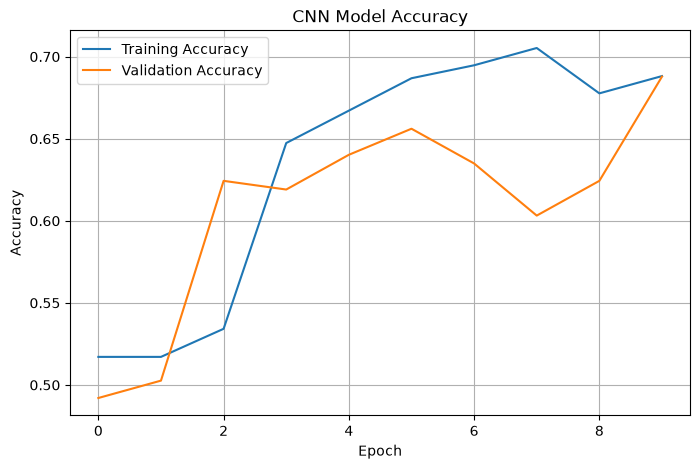

In [17]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## 10.2 Plot loss

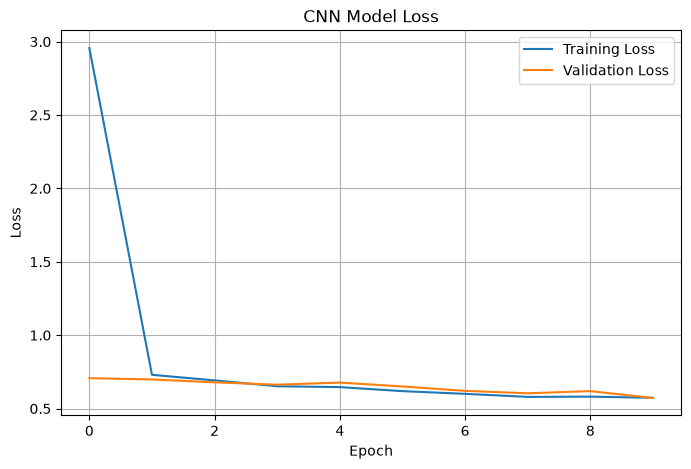

In [18]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

## Inference
The training and validation accuracy and loss curves were plotted to visualize the CNN model's learning behavior across epochs. The plots help assess the model's performance, identify improvements during training, and observe possible signs of overfitting or underfitting.

## 11. Save the Trained Model

## 11.1 Save model

In [19]:
# Save the trained CNN model

ARTIFACTS_PATH = PROJECT_ROOT / "Artifacts"
ARTIFACTS_PATH.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACTS_PATH / "railway_cnn_model.keras"

cnn_model.save(MODEL_PATH)

print("Model saved successfully!")
print("Saved model location:", MODEL_PATH)

Model saved successfully!
Saved model location: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\railway_cnn_model.keras


## 11.2 Save class names

In [20]:
# Save class names for future prediction

import json

CLASS_NAMES_PATH = ARTIFACTS_PATH / "class_names.json"

with open(CLASS_NAMES_PATH, "w") as file:
    json.dump(class_names, file, indent=4)

print("Class names saved successfully!")
print("Saved location:", CLASS_NAMES_PATH)

Class names saved successfully!
Saved location: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\class_names.json


## Inference
The trained CNN model was saved in the project artifacts directory in Keras format for future reuse. The class names were also saved separately in JSON format to preserve the mapping between model output predictions and railway image categories. These artifacts can be used for future model evaluation, image prediction, and API integration.

## 12. Final CNN Model Summary

In [21]:
# Final CNN model summary

final_train_accuracy = history.history["accuracy"][-1]
final_validation_accuracy = history.history["val_accuracy"][-1]

final_train_loss = history.history["loss"][-1]
final_validation_loss = history.history["val_loss"][-1]

print("=" * 50)
print("FINAL CNN MODEL SUMMARY")
print("=" * 50)

print("Number of classes        :", len(class_names))
print("Image size              :", IMAGE_SIZE)
print("Batch size              :", BATCH_SIZE)
print("Training epochs          :", EPOCHS)

print("-" * 50)

print(f"Final training accuracy  : {final_train_accuracy:.4f}")
print(f"Final validation accuracy: {final_validation_accuracy:.4f}")
print(f"Final training loss     : {final_train_loss:.4f}")
print(f"Final validation loss    : {final_validation_loss:.4f}")

print("-" * 50)

print("Model saved at:", MODEL_PATH)
print("Class names saved at:", CLASS_NAMES_PATH)

print("=" * 50)
print("CNN MODEL DEVELOPMENT COMPLETED")
print("=" * 50)

FINAL CNN MODEL SUMMARY
Number of classes        : 2
Image size              : (224, 224)
Batch size              : 32
Training epochs          : 10
--------------------------------------------------
Final training accuracy  : 0.6882
Final validation accuracy: 0.6878
Final training loss     : 0.5732
Final validation loss    : 0.5720
--------------------------------------------------
Model saved at: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\railway_cnn_model.keras
Class names saved at: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\class_names.json
CNN MODEL DEVELOPMENT COMPLETED


## Inference
The CNN model development workflow was completed, including architecture design, model compilation, training, performance visualization, and model saving. The final training and validation accuracy and loss values were recorded to summarize the model's learning performance. The trained model and class label information were stored in the artifacts directory for subsequent evaluation and deployment stages.